# Анализ признаков, отбор наиболее важных признаков, матрица корреляций, pairplot
Проанализируем признаки, чтобы оценить их связь с целевой переменной и выделить потенциально наиболее важные из них для решения нашей задачи. Построим матрицу взаимных корреляций этих признаков, а для самых "сильных" из них — матричный график диаграмм рассеяния (pairplot).

In [14]:
# загрузка библиотек и данных
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
#from sklearn.feature_selection import mutual_info_classif - пока не пользовались, но можно еще и так отобрать признаки попробовать...

In [15]:
# загрузка данных
from bitcoin_aml_detection.data import AGG_FEATURES, FEATURES, LOCAL_FEATURES, load_edges, load_txs
df = load_txs()

In [16]:
# посмотрим, что у нас загрузилось, все ли в порядке
df.shape

(203769, 169)

Для проведения корректного анализа важности признаков необходимо оставить в выборке только размеченные транзакции. Кроме того, важно учитывать, что в исследуемом датасете признаки делятся на две принципиально разные группы: локальные (описывающие параметры самой транзакции) и агрегированные (полученные путем сбора информации о соседних транзакциях на расстоянии одного и двух шагов по графу).

In [17]:
labeled_df = df[df["label"] != "unknown"].copy()

In [18]:
labeled_df.shape

(46564, 169)

Ранее обсуждалась важность разделения данных на два временных интервала, поскольку ряд признаков ведет себя на них заметно по-разному. Выделим два временных интервала по значению time_step: ранний период (шаги 1–34) и поздний период (шаги 35–49).

In [19]:
early_df = labeled_df[labeled_df["time_step"] <= 34].copy()
late_df = labeled_df[labeled_df["time_step"] >= 35].copy()

In [20]:
early_df.shape, late_df.shape

((29894, 169), (16670, 169))

Как уже отмечалось, некоторые признаки со временем могут заметно изменяться (их распределение сильно меняется от шага к шагу). Найдем такие признаки с помощью критерия Колмогорова-Смирнова, сравнив распределения в раннем и позднем периодах.

In [23]:
ks_results = []

for col in FEATURES:
    dist_early = early_df[col]
    dist_late = late_df[col]
    
    ks_stat, p_value = ks_2samp(dist_early, dist_late)
    
    ks_results.append({
        'feature': col,
        'ks_stat': ks_stat,
        'p_value': p_value
    })

df_ks = pd.DataFrame(ks_results).sort_values(by='ks_stat', ascending=False)

print(f"Нашлось признаков: {len(df_ks[df_ks['ks_stat'] >= 0.4])}")
print()
print(df_ks[df_ks['ks_stat'] >= 0.4])

Нашлось признаков: 16

     feature   ks_stat  p_value
100    agg_8  0.995741      0.0
102   agg_10  0.994841      0.0
135   agg_43  0.994441      0.0
99     agg_7  0.993101      0.0
138   agg_46  0.960153      0.0
136   agg_44  0.927873      0.0
1    local_2  0.656494      0.0
105   agg_13  0.601085      0.0
108   agg_16  0.552839      0.0
111   agg_19  0.501099      0.0
141   agg_49  0.493477      0.0
106   agg_14  0.488473      0.0
114   agg_22  0.485056      0.0
150   agg_58  0.459026      0.0
2    local_3  0.443535      0.0
147   agg_55  0.418803      0.0


Таким образом, у нас нашлось 16 признаков, которые существенно изменяются со временем (статистика Колмогорова-Смирнова >= 0.4). Если оставить их как есть, они могут исказить результаты при отборе наиболее информативных переменных, ошибочно оказавшись в числе лидеров из-за влияния фактора времени.  
Вместо механического исключения этих признаков (даже тех, у которых статистика Колмогорова-Смирнова близка к 1), мы попробуем обработать их следующим образом: для каждого временного шага (time_step) вычтем из признака значение его локальной медианы. Благодаря этому мы "очистим" переменные от привязки к абсолютному времени и будем анализировать только колебания признака относительно его "среднего уровня". Эта операция называется детрендированием.  
Важным преимуществом такого подхода является то, что признаки, обладающие минимальным внутренним разбросом (признаки «с лесенками» на графике boxplot'ов), после вычитания медианы фактически занулятся и в дальнейшем анализе уже никак не смогут претендовать на попадание в число наиболее важных.

In [24]:
drift_features = df_ks[df_ks['ks_stat'] >= 0.4]['feature'].tolist()

def detrend(df_target):
    df_res = df_target.copy()
    for col in drift_features:
        if col in df_res.columns:
            step_medians = df_res.groupby('time_step')[col].transform('median')
            df_res[col] = df_res[col] - step_medians
    return df_res

labeled_df_clean = detrend(labeled_df)
early_df_clean = detrend(early_df)
late_df_clean = detrend(late_df)

### Отбор признаков при помощи разности медиан
Теперь определим наиболее важные (информативные) признаки для всех трех очищенных датасетов. Сделаем это двумя способами.  
Первый способ - расчет устойчивой разности медиан. Если разность медиан велика, это свидетельствует о том, что данный признак должен эффективно разделять наши транзакции по классам. Для этого разделим каждый датасет на два подмножества: в одном будут только легальные (licit) транзакции, в другом - только мошеннические (illicit). Вычислим разность медиан каждого признака между этими группами.  
Чтобы исключить влияние разного масштаба признаков, мы стандартизируем эту разность: разделим её на межквартильный размах (IQR), посчитанный по всему текущему датасету. Поскольку некоторые признаки, как мы выяснили, являются квазиконстантными, их межквартильный размах может быть равен нулю. В таких случаях в качестве делителя мы будем использовать среднеквадратическое отклонение, чтобы избежать ошибки деления на ноль.

In [27]:
def importance(df, features, target_col='y'):
    results = []
    
    df_illicit = df[df[target_col] == 1]
    df_licit = df[df[target_col] == 0]
    
    for col in features:
        med_illicit = df_illicit[col].median()
        med_licit = df_licit[col].median()
        
        q75, q25 = np.percentile(df[col], [75, 25])
        iqr = q75 - q25

        if iqr == 0:
            iqr = df[col].std()
        
        # если, вдруг, окажется, что и std() == 0
        if iqr == 0:
            delta = 0.0
        else:
            delta = abs(med_illicit - med_licit) / iqr

        results.append({
            'feature': col,
            'delta': delta
        })
        
    return pd.DataFrame(results).set_index('feature')

imp_all = importance(labeled_df_clean, FEATURES)
imp_early = importance(early_df_clean, FEATURES)
imp_late = importance(late_df_clean, FEATURES)

df_importance_report = pd.DataFrame(index=FEATURES)
df_importance_report['Imp_All'] = imp_all['delta']
df_importance_report['Imp_Early'] = imp_early['delta']
df_importance_report['Imp_Late'] = imp_late['delta']

df_importance_report = df_importance_report.sort_values(by='Imp_All', ascending=False)

print(df_importance_report.head(10))

           Imp_All  Imp_Early  Imp_Late
local_76  5.500000   1.444444  0.000429
agg_49    3.271614   3.375163  4.356586
agg_61    3.000000   2.666667  3.750000
local_58  1.408424   0.735025  3.043228
local_64  1.407678   0.734011  2.938360
agg_37    1.314235   1.221426  1.046220
agg_67    1.000000   1.000000  0.000000
agg_69    0.816497   0.000000  0.333333
agg_70    0.750000   1.000000  0.000000
local_4   0.500000   0.500000  0.000000


В итоговой десятке нашлось 6 агрегированных признаков и 4 локальных. Отчетливо видно, что у ряда переменных важность не остается постоянной во времени. Наример, лидер рейтинга (local_76) демонстрирует снижение своей важности практически до нуля в поздний период. Следовательно, есть смысл провести дополнительную фильтрацию нашего списка признаков с учетом таких колебаний.  
В качестве порогового критерия стабильной важности выберем значение 0.5 - именно эта оценка позволила признаку local_4 занять 10-е место на общем датасете. Будем считать признак устойчивым, если его важность превосходит или равна 0.5 как в раннем, так и в позднем периодах одновременно.

In [28]:
threshold = 0.5

robust_features = df_importance_report[
    (df_importance_report['Imp_Early'] >= threshold) & 
    (df_importance_report['Imp_Late'] >= threshold)
].sort_values(by='Imp_All', ascending=False)

print(robust_features)

           Imp_All  Imp_Early  Imp_Late
agg_49    3.271614   3.375163  4.356586
agg_61    3.000000   2.666667  3.750000
local_58  1.408424   0.735025  3.043228
local_64  1.407678   0.734011  2.938360
agg_37    1.314235   1.221426  1.046220


В результате фильтрации у нас осталось 5 признаков: 3 агрегированных и 2 локальных. Теперь проверим, есть ли пересечения между ними и признаками, которые мы детрендировали на предыдущем шаге.

In [30]:
top_median = robust_features.index.tolist()
intersected_features = list(set(top_median).intersection(set(drift_features)))
print(f"Найдено пересечений: {len(intersected_features)}")

if len(intersected_features) > 0:
    for f in intersected_features:
        print(f)

Найдено пересечений: 1
agg_49


Найдено ровно одно пересечение. Этот признак оказался единственным, сохранившим высокую предсказательную способность после очистки от влияния временного тренда (детрендирования), поэтому мы будем использовать его в дальнейшем анализе.

### Отбор признаков при помощи коэффициента корреляции
Теперь определим наиболее важные признаки по их корреляции с целевой переменной. Для этого используем ранговый коэффициент Спирмена, так как распределения большинства признаков в датасете сильно скошены, многие содержат выбросы. Подробнее об этом говорилось в предыдущих частях работы.

In [31]:
corr_all = labeled_df_clean[FEATURES].corrwith(labeled_df_clean['y'], method='spearman')
corr_early = early_df_clean[FEATURES].corrwith(early_df_clean['y'], method='spearman')
corr_late = late_df_clean[FEATURES].corrwith(late_df_clean['y'], method='spearman')

df_corr_report = pd.DataFrame(index=FEATURES)
df_corr_report['Corr_All_Abs'] = corr_all.abs()
df_corr_report['Corr_Early_Abs'] = corr_early.abs()
df_corr_report['Corr_Late_Abs'] = corr_late.abs()

df_corr_report = df_corr_report.sort_values(by='Corr_All_Abs', ascending=False)

print(df_corr_report.head(10))

          Corr_All_Abs  Corr_Early_Abs  Corr_Late_Abs
local_14      0.417098        0.418147       0.399082
local_5       0.417030        0.418132       0.398880
local_90      0.353160        0.368899       0.329077
local_53      0.345146        0.393265       0.261710
local_55      0.333374        0.372887       0.266840
local_66      0.329627        0.345348       0.307373
local_60      0.329609        0.345368       0.307217
local_29      0.326249        0.341953       0.305816
local_23      0.326239        0.341941       0.305832
agg_39        0.324176        0.339528       0.267128


В итоговой десятке по корреляции Спирмена нашлось 9 локальных признаков и всего 1 агрегированный. Таким образом, данный метод отдает явное предпочтение локальным переменным. По всей видимости, локальные признаки обладают более гладким и монотонным распределением, что позволяет ранговому коэффициенту лучше улавливать их связь с целевой переменной на всем протяжении данных.  
Также отчетливо видно, что в отличие от оценок важности с помощью разности медиан, ранговая корреляция этих признаков относительно стабильна во времени.

Также мы видим, что у некоторых признаков коэффициенты корреляции с таргетом совпадают с точностью до четвертого знака после запятой. К таким парам относятся: local_14 и local_5, local_66 и local_60, а также local_29 и local_23. Проверим эти переменные на мультиколлинеарность, рассчитав матрицу их взаимной ранговой корреляции.

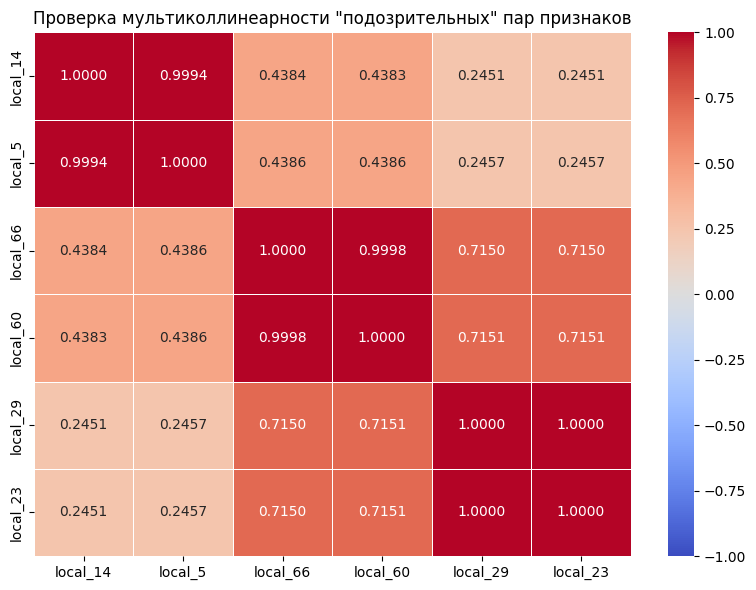

In [32]:
target_pairs = ['local_14', 'local_5', 'local_66', 'local_60', 'local_29', 'local_23']

pair_corr_matrix = labeled_df_clean[target_pairs].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(pair_corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.4f', linewidths=0.5)
plt.title('Проверка мультиколлинеарности "подозрительных" пар признаков')
plt.tight_layout()
plt.show()

Матрица показывает, что у всех трех пар коэффициент корреляции практически равен 1 (или даже просто равен 1). Для дальнейшего анализа следует использовать только какой-то 1 признак из каждой пары.

Проверим, пересекаются ли наборы наиболее информативных признаков, полученные двумя методами: с помощью разности медиан и на основе ранговой корреляции Спирмена.

In [34]:
top_spearman = df_corr_report.sort_values(by='Corr_All_Abs', ascending=False).head(10).index.tolist()
common_features = list(set(top_median).intersection(set(top_spearman)))

only_in_medians = list(set(top_median).difference(set(top_spearman)))
only_in_spearman = list(set(top_spearman).difference(set(top_median)))

print(f"Общие признаки (совпали в обоих методах): {len(common_features)}")
print(common_features)
print()
print(f"Уникальные для метода разности медиан: {only_in_medians}")
print(f"Уникальные для метода корреляции: {only_in_spearman}")

Общие признаки (совпали в обоих методах): 0
[]

Уникальные для метода разности медиан: ['local_64', 'local_58', 'agg_37', 'agg_61', 'agg_49']
Уникальные для метода корреляции: ['local_60', 'local_14', 'local_66', 'local_53', 'local_55', 'local_90', 'local_23', 'local_5', 'agg_39', 'local_29']


Как мы видим, взаимных пересечений двух методов не обнаружилось. Метод разности медиан сфокусирован на поиске резких разрывов между классами и выделил преимущественно агрегированные признаки. Ранговый метод Спирмена, напротив, в основном отобрал локальные признаки. Это указывает на наличие стабильной монотонной связи между внутренними параметрами транзакций и их классом.

### Матричный график диаграмм рассеяния
В итоге нам удалось выявить 12 признаков, интересных для дальнейшего анализа: 5 - методом, основанным на разности медиан, и 7 - с помощью коэффициента ранговой корреляции Спирмена. Выберем из них два агрегированных признака (agg_49, agg_61) и два локальных (local_14, local_90). Это лидеры, занявшие 1-е и 2-е места в соответствующих рейтингах важности.  
По этим признакам построим график диаграмм рассеяния (pairplot). Поскольку классы в исходном датасете сильно несбалансированы, выберем по 2000 случайных транзакций для каждой из категорий (licit и illicit). Такой подход поможет избежать наложения точек и обеспечит наилучшее визуальное разделение классов на графиках.

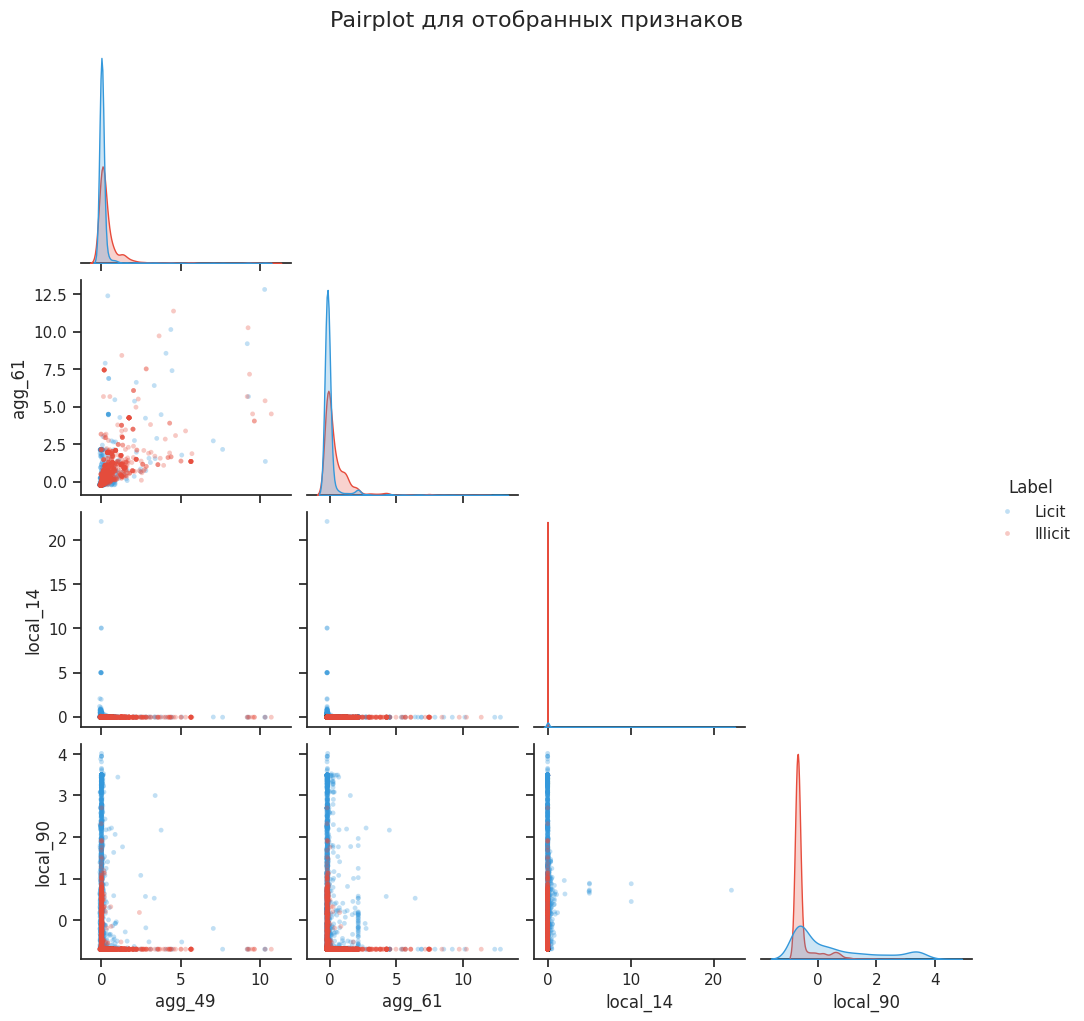

In [35]:
final_features = ['agg_49', 'agg_61', 'local_14', 'local_90']

n_samples = 2000
df_sampled = (
    labeled_df_clean.groupby('y')
    .apply(lambda x: x.sample(n=min(len(x), n_samples), random_state=42), include_groups=False)
    .reset_index(level=0)
)

df_sampled['Label'] = df_sampled['y'].map({1: 'Illicit', 0: 'Licit'})

sns.set_theme(style="ticks")

g = sns.pairplot(
    df_sampled, 
    vars=final_features, 
    hue='Label', 
    palette={'Illicit': '#e74c3c', 'Licit': '#3498db'}, 
    plot_kws={'alpha': 0.3, 's': 12, 'edgecolor': 'none'},
    diag_kind='kde',
    corner=True
)

g.fig.suptitle('Pairplot для отобранных признаков', y=1.02, fontsize=16)
plt.show()

При анализе построенного графика pairplot отчетливо видна специфика распределения плотности легальных и мошеннических транзакций, которая кардинально меняется в зависимости от типа признака:  
  
**Агрегированные признаки**  
Пик плотности легальных транзакций расположен примерно в той же области, что и у мошеннических, но выражен заметно сильнее и выше. При этом распределение нелегальных транзакций относительно смещено вправо. Это можно интерпретировать так. Подавляющее большинство честных пользователей имеют стандартное, однородное сетевое окружение (например, взаимодействуют только с крупными известными сервисами). В свою очередь, смещенное вправо распределение мошеннических транзакций может показывать наличие аномально плотных преступных подграфов и многоуровневых цепочек кошельков, создаваемых для запутывания следов.  
  
**Локальные признаки**  
Здесь наблюдается зеркально противоположная картина. Пик мошеннических транзакций существенно превосходит по высоте пик легальных, при этом легальные транакции относительно смещены вправо. Это можно попытаться объяснить следующим образом. Мошенники действуют скрытно, а значит, их транзакции стремятся походить на среднестатистического мелкого пользователя, что делает их параметры их однообразными (высокий узкий пик). Напротив, легальные транзакции могут быть более разнообразны, их распределение смещается вправо за счет присутствия институциональных участников сети биткоина (например, крупных бирж), которые оперируют большими объемами средств и могут генерировать транзакции с сотнями входов и выходов.
  
**Синергетический эффект на диаграммах рассеяния**  
Судя по диаграммам рассеяния (scatter plots), изолированное использование пар только агрегированных или только локальных признаков не обеспечивает четкого разграничения классов транзакций. Более качественный результат достигается именно при совместном использовании локальных и агрегированных признаков, что может быть важно для успешного обучения будущих моделей классификации.
  

### Матрица взаимных корреляций
Для комплексной оценки структуры взаимосвязей и выявления скрытых зависимостей построим полную матрицу взаимных корреляций Спирмена для всех 12 отобранных признаков, включив в неё также целевую переменную. Это позволит нам одновременно увидеть характер связи каждой переменной с таргетом и оценить уровень внутренней мультиколлинеарности данных.

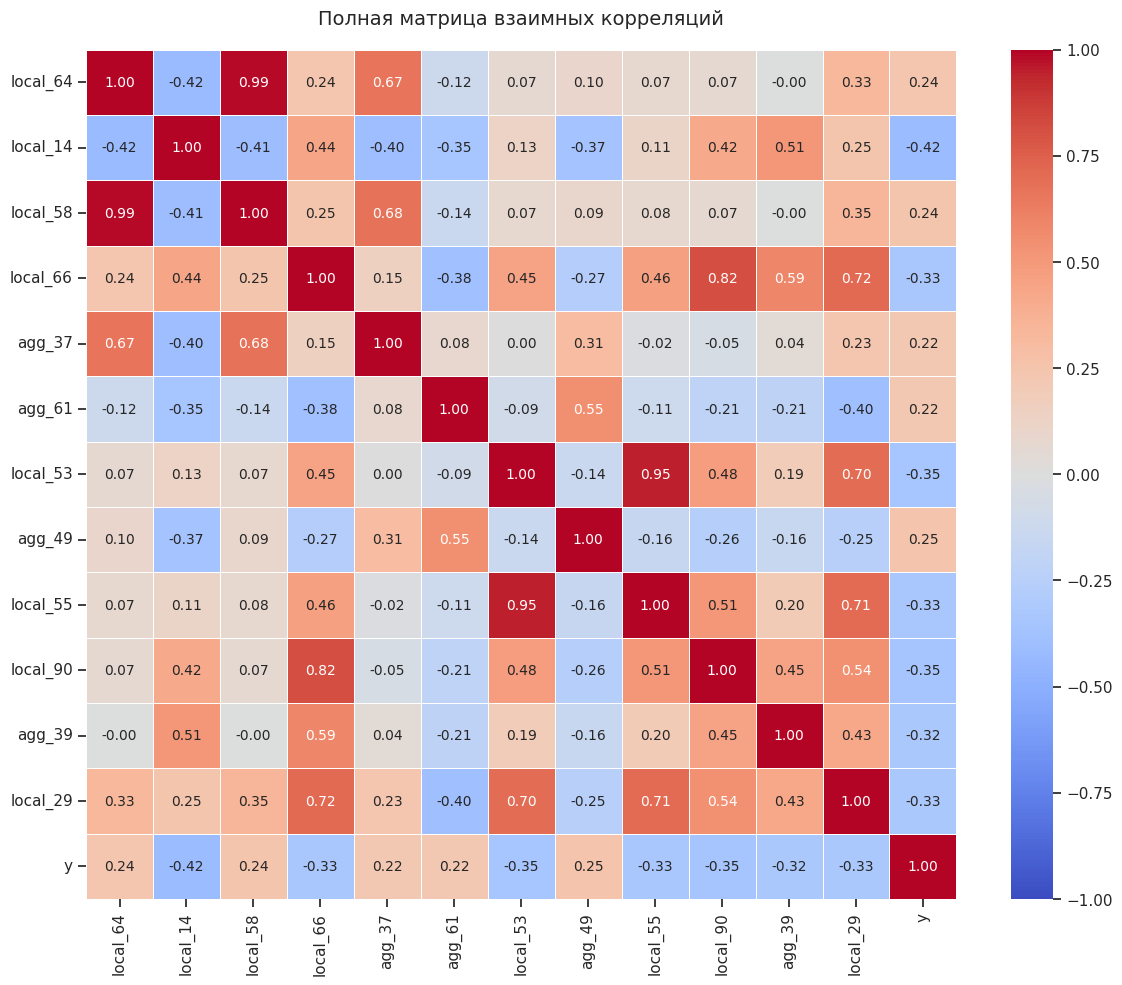

In [37]:
top_median_list = ['agg_49', 'agg_61', 'local_58', 'local_64', 'agg_37']
top_spearman_list = ['local_14', 'local_90', 'local_53', 'local_55', 'local_66', 'local_29', 'agg_39']
selected_features = list(set(top_median_list + top_spearman_list))
with_target = selected_features + ['y']

full_corr_matrix = labeled_df_clean[with_target].corr(method='spearman')

plt.figure(figsize=(12, 10))

sns.heatmap(
    full_corr_matrix, 
    annot=True,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    fmt='.2f',
    linewidths=0.5,
    annot_kws={"size": 10}
)

plt.title('Полная матрица взаимных корреляций', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Анализ построенной матрицы позволяет сделать следующие выводы:  
  
**Внутренняя коллинеарность**  
Мы обнаружили еще две пары потенциально мультиколлинеарных локальных признаков с высокой взаимной корреляцией (>= 0.95): это local_53 и local_55, а также local_64 и local_58. Из каждой пары целесообразно исключить по одной переменной. В результате мы получим набор из 10 признаков, который может стать основой для построения базовой модели классификации (baseline).  
  
**Сила связи с целевой переменной**  
Коэффициенты корреляции отобранных признаков с целевой переменной по модулю находятся в диапазоне от 0.22 до 0.42. Для данных о реальных транзакциях в блокчейне, которые неизбежно содержат высокий уровень естественного шума, это можно считать хорошим результатом.  
  
**Характер влияния по знакам корреляции**  
Поскольку мошеннические транзакции закодированы как 1, а легальные — как 0, знаки корреляции можно интерпретировать:
* Положительный знак указывает на то, что высокие значения данных параметров характерны для мошеннических транзакций.
* Отрицательный знак означает обратную зависимость: высокие значения данных признаков свойственны легальным транзакциям.